# Polymarket Insider Trade Detector
Run each cell in order.

In [ ]:
# CELL 1 — IMPORTS & CONFIG
import requests
import sqlite3
import json
import time
from datetime import datetime

import pandas as pd
import numpy as np

GAMMA_API  = "https://gamma-api.polymarket.com"
DATA_API   = "https://data-api.polymarket.com" 
DB_PATH    = "polymarket.db"
HEADERS    = {"User-Agent": "Mozilla/5.0", "Accept": "application/json"}

TOP_N_MARKETS     = 2000
TRADES_PER_MARKET = 1000

print("Ready.")

Ready.


In [2]:
# CELL 2 — SET UP DATABASE
conn = sqlite3.connect(DB_PATH)

for table in ["markets", "trades", "wallet_stats", "flagged_trades"]:
    conn.execute(f"DROP TABLE IF EXISTS {table}")
conn.commit()

print("DB ready.")

DB ready.


In [3]:
# CELL 3 — FETCH MARKETS
r = requests.get(
    f"{GAMMA_API}/markets",
    params={"active": "true", "closed": "false",
            "limit": TOP_N_MARKETS, "order": "volume1wk", "ascending": "false"},
    headers=HEADERS,
    timeout=15,
)

#"order": "volume24hr"   # hottest in last 24 hours
#"order": "volume1wk"    # hottest this week
#"order": "volume1mo"    # hottest this month

raw_markets = r.json()

# filtering out the sports markets 

SPORTS_KEYWORDS = [
    "nba", "nfl", "nhl", "mlb", "soccer", "football", "basketball",
    "baseball", "hockey", "tennis", "golf", "ufc", "mma", "wrestling",
    "fifa", "wimbledon", "superbowl", "champions league", "premier league",
    "score", "match", "game", "playoff", "championship", "tournament",
    "over/under", "total kills", "lol-dnf"
]

def is_sports(market):
    text = (market.get("question", "") + market.get("slug", "")).lower()
    return any(kw in text for kw in SPORTS_KEYWORDS)

raw_markets = [m for m in raw_markets if not is_sports(m)]
 

markets = []
for m in raw_markets:
    token_ids      = json.loads(m.get("clobTokenIds", "[]"))
    outcome_prices = json.loads(m.get("outcomePrices", '["0.5","0.5"]'))

    markets.append({
        "condition_id":     m.get("conditionId", ""),
        "question":         m.get("question", ""),
        "end_date":         m.get("endDate", ""),
        "volume":           float(m.get("volume") or 0),
        "liquidity":        float(m.get("liquidityNum") or 0),
        "yes_price":        float(outcome_prices[0]),
        "no_price":         float(outcome_prices[1]),
        "best_bid":         float(m.get("bestBid") or 0),
        "best_ask":         float(m.get("bestAsk") or 0),
        "last_trade_price": float(m.get("lastTradePrice") or 0),
        "yes_token_id":     token_ids[0] if token_ids else "",
        "no_token_id":      token_ids[1] if len(token_ids) > 1 else "",
    })

markets_df = pd.DataFrame(markets)
markets_df.to_sql("markets", conn, if_exists="replace", index=False)
conn.commit()

print(f"Saved {len(markets_df)} markets.")
markets_df[["question", "volume", "liquidity", "yes_price"]].head()

Saved 87 markets.


,question,volume,liquidity,yes_price
0,Will Demeke Mekonnen be the next Prime Ministe...,2.672627e+07,21432.97773,0.0035
1,Will there be no change in Fed interest rates ...,2.732887e+07,450842.19702,0.7525
2,Will Adanech Abiebie be the next Prime Ministe...,4.807222e+07,32719.44559,0.0020
3,Will the Fed increase interest rates by 50+ bp...,1.800073e+07,723315.86715,0.0075
4,Will the Fed increase interest rates by 25 bps...,1.841422e+07,375443.09207,0.2405


In [4]:
# CELL 3b — FETCH CLOSED MARKETS (for ground-truth backtesting)
r = requests.get(
    f"{GAMMA_API}/markets",
    params={"closed": "true",
            "limit": TOP_N_MARKETS, "order": "volume", "ascending": "false"},
    headers=HEADERS,
    timeout=15,
)
raw_closed_markets = r.json()
raw_closed_markets = [m for m in raw_closed_markets if not is_sports(m)]

closed_markets = []
for m in raw_closed_markets:
    token_ids      = json.loads(m.get("clobTokenIds", "[]"))
    outcome_prices = json.loads(m.get("outcomePrices", '["0.5","0.5"]'))

    closed_markets.append({
        "condition_id":     m.get("conditionId", ""),
        "question":         m.get("question", ""),
        "end_date":         m.get("endDate", ""),
        "volume":           float(m.get("volume") or 0),
        "liquidity":        float(m.get("liquidityNum") or 0),
        "best_bid":         float(m.get("bestBid") or 0),
        "best_ask":         float(m.get("bestAsk") or 0),
        "final_yes_price":  float(outcome_prices[0]),
        "final_no_price":   float(outcome_prices[1]),
        "yes_token_id":     token_ids[0] if token_ids else "",
        "no_token_id":      token_ids[1] if len(token_ids) > 1 else "",
    })

closed_markets_df = pd.DataFrame(closed_markets)
print(f"Pulled {len(closed_markets)} closed markets")


Pulled 50 closed markets


In [5]:
# CELL 4 — FETCH TRADES  (takes a few minutes)
all_trades = []

for i, m in enumerate(markets):
    cid = m["condition_id"]
    print(f"({i+1}/{len(markets)}) {m['question'][:60]}...")

    offset = 0
    while offset < TRADES_PER_MARKET:
        r = requests.get(
            f"{DATA_API}/trades",
            params={"market": cid, "limit": 500, "offset": offset},
            headers=HEADERS,
            timeout=15,
        )
        if not r.ok:
            break

        page = r.json()
        if not page:
            break

        for t in page:
            tx    = t.get("transactionHash", "")
            asset = t.get("asset", "")
            all_trades.append({
                "trade_id":     f"{tx[:20]}_{asset[:10]}",
                "condition_id": cid,
                "wallet":       t.get("proxyWallet", ""),
                "side":         t.get("side", ""),
                "outcome":      t.get("outcome", ""),
                "price":        float(t.get("price") or 0),
                "size":         float(t.get("size") or 0),
                "timestamp":    int(t.get("timestamp") or 0),
                "tx_hash":      tx,
                "market_title": t.get("title", ""),
            })

        if len(page) < 500:
            break
        offset += 500
        time.sleep(0.2)

    print(f"   -> {len([t for t in all_trades if t['condition_id'] == cid])} trades")
    time.sleep(0.4)

trades_df = pd.DataFrame(all_trades).drop_duplicates(subset="trade_id")
trades_df.to_sql("trades", conn, if_exists="replace", index=False)
conn.commit()

print(f"\nTotal trades saved: {len(trades_df)}")
trades_df.head()

(1/87) Will Demeke Mekonnen be the next Prime Minister of Ethiopia?...
   -> 1000 trades
(2/87) Will there be no change in Fed interest rates after the July...
   -> 1000 trades
(3/87) Will Adanech Abiebie be the next Prime Minister of Ethiopia?...
   -> 1000 trades
(4/87) Will the Fed increase interest rates by 50+ bps after the Ju...
   -> 1000 trades
(5/87) Will the Fed increase interest rates by 25 bps after the Jul...
   -> 1000 trades
(6/87) Will the Fed decrease interest rates by 25 bps after the Jul...
   -> 1000 trades
(7/87) Will LeBron James play for the Miami Heat in 2026-27?...
   -> 1000 trades
(8/87) Will the U.S. invade Iran before 2027?...
   -> 1000 trades
(9/87) Strait of Hormuz traffic returns to normal by July 31?...
   -> 1000 trades
(10/87) Will the Fed decrease interest rates by 50+ bps after the Ju...
   -> 1000 trades
(11/87) LoL: Top Esports vs ThunderTalk Gaming (BO3) - LPL Group Asc...
   -> 1000 trades
(12/87) Will LeBron James play for the Golden State Wa

,trade_id,condition_id,wallet,side,outcome,price,size,timestamp,tx_hash,market_title
0,0xbf4f2095a30c14b3a3_1008108723,0xf5ee4b6bd7d585c0e12e530074d0324493c302b82e12...,0x379e4e2a6c283661a0a20702138d3ca2baaa8fbe,BUY,No,0.997000,378.134333,1784969791,0xbf4f2095a30c14b3a34139b7a41f856dd70ec98bdab0...,Will Demeke Mekonnen be the next Prime Ministe...
1,0xa994710141a9997a33_1008108723,0xf5ee4b6bd7d585c0e12e530074d0324493c302b82e12...,0x379e4e2a6c283661a0a20702138d3ca2baaa8fbe,BUY,No,0.997000,1003.009000,1784968476,0xa994710141a9997a3319334551967558837c72363c0c...,Will Demeke Mekonnen be the next Prime Ministe...
2,0xce3accf7dbc3450b50_2782564244,0xf5ee4b6bd7d585c0e12e530074d0324493c302b82e12...,0xfff8f929f5b5e1dcb9ba43519a00781961d8d922,SELL,Yes,0.003000,506.600000,1784949289,0xce3accf7dbc3450b508469346951f35e86b6bdc857ce...,Will Demeke Mekonnen be the next Prime Ministe...
3,0x05562729a4ee0c697b_1008108723,0xf5ee4b6bd7d585c0e12e530074d0324493c302b82e12...,0x73bd36350c6fbbf021115abdfa0a66f61c21f55c,SELL,No,0.982937,700.000000,1784901936,0x05562729a4ee0c697b4079bda334336dea78eac5674a...,Will Demeke Mekonnen be the next Prime Ministe...
4,0x13efc5d4a26b74a1eb_1008108723,0xf5ee4b6bd7d585c0e12e530074d0324493c302b82e12...,0x73bd36350c6fbbf021115abdfa0a66f61c21f55c,BUY,No,0.996000,700.000000,1784901885,0x13efc5d4a26b74a1eb58f5fe00422f19af6b2153ff9e...,Will Demeke Mekonnen be the next Prime Ministe...


In [6]:
# CELL 5 — WALLET STATS
wallet_stats = trades_df.groupby("wallet").agg(
    total_trades   = ("size", "count"),
    total_volume   = ("size", "sum"),
    avg_trade_size = ("size", "mean"),
    max_trade_size = ("size", "max"),
    markets_traded = ("condition_id", "nunique"),
    first_seen     = ("timestamp", "min"),
    last_seen      = ("timestamp", "max"),
    buy_count      = ("side", lambda x: (x == "BUY").sum()),
    sell_count     = ("side", lambda x: (x == "SELL").sum()),
).reset_index()

wallet_stats["buy_ratio"] = (
    wallet_stats["buy_count"] /
    (wallet_stats["buy_count"] + wallet_stats["sell_count"]).clip(lower=1)
)

wallet_stats.to_sql("wallet_stats", conn, if_exists="replace", index=False)
conn.commit()

print(f"Stats for {len(wallet_stats)} wallets.")
wallet_stats.sort_values("total_volume", ascending=False).head()

Stats for 17782 wallets.


,wallet,total_trades,total_volume,avg_trade_size,max_trade_size,markets_traded,first_seen,last_seen,buy_count,sell_count,buy_ratio
16793,0xf1a6155623d4c21461d0d71a20ffc17ad20a807c,720,3.672000e+06,5100.000000,5100.00,2,1784732470,1784983293,0,720,0.0
9955,0x8ec829f01516095606e4c265768d75238ebf5709,8,2.033317e+06,254164.668942,1095032.22,2,1784603767,1784605579,8,0,1.0
5578,0x4f423d4ad987215b20b95f788f83c250e9628bbc,24,9.789862e+05,40791.092385,226543.75,11,1784756422,1784861136,24,0,1.0
862,0x0bb8a71b7ed93265c8045640fb3aa1eb93ad253e,4,8.556871e+05,213921.765000,500000.00,3,1784811343,1784957221,4,0,1.0
12677,0xb687f00464e33934f5d591f224e71c3559ecaee5,1799,6.682121e+05,371.435297,25238.39,24,1783028782,1784998711,0,1799,0.0


In [ ]:
# CELL 5b — ENRICH TOP SUSPICIOUS WALLETS
# For each suspicious wallet, fetch:
#   1. Their full trade history across ALL markets (not just the 20 we pulled)
#   2. Their current open positions
# This gives us a true win rate and concentration score.

# Pick top 20 wallets by volume to enrich — adjust as needed
TOP_WALLETS_TO_ENRICH = 20

top_wallets = (
    wallet_stats
    .sort_values("total_volume", ascending=False)
    .head(TOP_WALLETS_TO_ENRICH)["wallet"]
    .tolist()
)

print(f"Enriching {len(top_wallets)} wallets...\n")

wallet_histories = []   # all historical trades per wallet
wallet_positions = []   # current open positions per wallet

for i, wallet in enumerate(top_wallets):
    print(f"({i+1}/{len(top_wallets)}) {wallet[:20]}...")

    # --- full trade history ---
    r_trades = requests.get(
        f"{DATA_API}/trades",
        params={"maker": wallet, "limit": 500},
        headers=HEADERS,
        timeout=15,
    )
    if r_trades.ok:
        history = r_trades.json()
        history = history if isinstance(history, list) else history.get("data", [])
        for t in history:
            wallet_histories.append({
                "wallet":       wallet,
                "condition_id": t.get("conditionId", ""),
                "market_title": t.get("title", ""),
                "side":         t.get("side", ""),
                "outcome":      t.get("outcome", ""),
                "price":        float(t.get("price") or 0),
                "size":         float(t.get("size") or 0),
                "timestamp":    int(t.get("timestamp") or 0),
            })
        print(f"   trades: {len(history)}")
    else:
        print(f"   trades: failed ({r_trades.status_code})")

    # --- open positions ---
    r_pos = requests.get(
        f"{DATA_API}/positions",
        params={"user": wallet, "sizeThreshold": 0},
        headers=HEADERS,
        timeout=15,
    )
    if r_pos.ok:
        positions = r_pos.json()
        positions = positions if isinstance(positions, list) else positions.get("data", [])
        for p in positions:
            wallet_positions.append({
                "wallet":         wallet,
                "condition_id":   p.get("conditionId", ""),
                "market_title":   p.get("title", ""),
                "outcome":        p.get("outcome", ""),
                "size":           float(p.get("size") or 0),
                "avg_price":      float(p.get("avgPrice") or p.get("averagePrice") or 0),
                "current_price":  float(p.get("currentPrice") or p.get("price") or 0),
                "unrealised_pnl": float(p.get("unrealizedPnl") or 0),
                "end_date":       p.get("endDate", ""),
            })
        print(f"   positions: {len(positions)}")
    else:
        print(f"   positions: failed ({r_pos.status_code})")

    time.sleep(0.4)

# Save both to DB
history_df   = pd.DataFrame(wallet_histories)
positions_df = pd.DataFrame(wallet_positions)

if not history_df.empty:
    history_df.to_sql("wallet_histories", conn, if_exists="replace", index=False)
    conn.commit()

if not positions_df.empty:
    positions_df.to_sql("wallet_positions", conn, if_exists="replace", index=False)
    conn.commit()

print(f"\nSaved {len(history_df)} historical trades across {len(top_wallets)} wallets.")
print(f"Saved {len(positions_df)} open positions.")

In [ ]:
# CELL 5c — COMPUTE WIN RATE & POSITION RISK PER WALLET
# Win rate = how often did this wallet bet on the winning outcome?
# We approximate using resolved markets in their history.
# Position risk = large open position close to resolution = red flag.

if history_df.empty:
    print("No history to compute — run Cell 4b first.")
else:
    # Markets where price is near 0 or 1 are effectively resolved
    # YES outcome at price > 0.85 = winning bet on YES
    # YES outcome at price < 0.15 = winning bet on NO
    hist = history_df.copy()

    hist["likely_winner"] = (
        ((hist["outcome"].str.lower().isin(["yes", "up"])) & (hist["price"] >= 0.85)) |
        ((hist["outcome"].str.lower().isin(["no", "down"])) & (hist["price"] <= 0.15))
    )
    hist["near_resolved"] = (hist["price"] >= 0.85) | (hist["price"] <= 0.15)

    win_rates = hist.groupby("wallet").agg(
        history_total_trades  = ("size", "count"),
        history_total_volume  = ("size", "sum"),
        history_markets       = ("condition_id", "nunique"),
        resolved_trade_count  = ("near_resolved", "sum"),
        winning_trade_count   = ("likely_winner", "sum"),
    ).reset_index()

    win_rates["approx_win_rate"] = (
        win_rates["winning_trade_count"] /
        win_rates["resolved_trade_count"].clip(lower=1)
    ).round(3)

    # Flag large open positions close to resolution
    if not positions_df.empty:
        pos = positions_df.copy()
        pos["end_dt"] = pd.to_datetime(pos["end_date"], utc=True, errors="coerce")
        pos["days_to_resolution"] = (
            pos["end_dt"] - pd.Timestamp.now(tz="UTC")
        ).dt.total_seconds() / 86400

        # High risk = large position + resolves within 7 days
        pos["high_risk_position"] = (
            (pos["size"] > pos["size"].quantile(0.9)) &
            (pos["days_to_resolution"] < 7) &
            (pos["days_to_resolution"] >= 0)
        )

        risk_summary = pos.groupby("wallet").agg(
            open_positions      = ("size", "count"),
            total_position_size = ("size", "sum"),
            high_risk_count     = ("high_risk_position", "sum"),
        ).reset_index()

        win_rates = win_rates.merge(risk_summary, on="wallet", how="left")

    win_rates.to_sql("wallet_enriched", conn, if_exists="replace", index=False)
    conn.commit()

    print(f"Win rates computed for {len(win_rates)} wallets.")
    print("\nTop wallets by approx win rate (min 5 resolved trades):")
    display(
        win_rates[win_rates["resolved_trade_count"] >= 5]
        .sort_values("approx_win_rate", ascending=False)
        .head(10)
    )

Win rates computed for 20 wallets.

Top wallets by approx win rate (min 5 resolved trades):


,wallet,history_total_trades,history_total_volume,history_markets,resolved_trade_count,winning_trade_count,approx_win_rate,open_positions,total_position_size,high_risk_count
0,0x011f2d377e56119fb09196dffb0948ae55711122,500,58901.948678,144,244,32,0.131,100.0,7.828935e+06,0.0
1,0x02401f7c65ed0d3cc39db73de727991bea6678f2,500,58901.948678,144,244,32,0.131,100.0,4.912784e+04,0.0
2,0x0bb8a71b7ed93265c8045640fb3aa1eb93ad253e,500,58901.948678,144,244,32,0.131,5.0,6.968828e+06,4.0
3,0x122cb94c437ea5e6f088c6c0c143c592ab8efbed,500,58901.948678,144,244,32,0.131,100.0,3.510866e+05,0.0
4,0x15e6ddfd2fa2e656e64e6fab9b04866618f83c2b,500,58901.948678,144,244,32,0.131,11.0,3.388431e+04,0.0
5,0x47e6d461c40169233b41ea6cdad6b6cb8126fd61,500,58901.948678,144,244,32,0.131,52.0,9.620836e+05,1.0
6,0x4f423d4ad987215b20b95f788f83c250e9628bbc,500,58901.948678,144,244,32,0.131,100.0,2.189328e+06,0.0
7,0x6916cc00aa1c3e75ecf4081df7cae7d2f3592fd4,500,58901.948678,144,244,32,0.131,76.0,3.051196e+05,0.0
8,0x695592ec786d39aadf4ada4e67c49d1f4f1d867a,500,58901.948678,144,244,32,0.131,1.0,9.520000e+03,0.0
9,0x7623426bd2058373e2374d1271f88b454ea6e75e,500,58901.948678,144,244,32,0.131,NaN,NaN,NaN


In [ ]:
# CELL 6 — OUTLIER DETECTION (Z-SCORE BASELINE)
flagged = []

for cid, group in trades_df.groupby("condition_id"):
    sizes = group["size"].values
    if len(sizes) < 10:
        continue

    median = np.median(sizes)
    mad    = np.median(np.abs(sizes - median))
    if mad == 0:
        continue
 
    z_scores = 0.6745 * (sizes - median) / mad
    group = group.copy()
    group["z_score"] = z_scores

    for _, row in group[group["z_score"] > 2.5].iterrows():
        flagged.append({
            "trade_id":     row["trade_id"],
            "condition_id": cid,
            "wallet":       row["wallet"],
            "size":         row["size"],
            "side":         row["side"],
            "outcome":      row["outcome"],
            "price":        row["price"],
            "z_score":      round(float(row["z_score"]), 4),
            "market_title": row["market_title"],
        })

flagged_df = pd.DataFrame(flagged)
if not flagged_df.empty:
    flagged_df.to_sql("flagged_trades", conn, if_exists="replace", index=False)
    conn.commit()

print(f"Flagged {len(flagged_df)} outlier trades.")
flagged_df.sort_values("z_score", ascending=False).head(10)

Flagged 21517 outlier trades.


,trade_id,condition_id,wallet,size,side,outcome,price,z_score,market_title
21359,0x9c18f22c08b4d271ac_4999047257,0xfd6176f8c9a59105f80e060a77c4099881c5f2d9e0ce...,0x8ec829f01516095606e4c265768d75238ebf5709,1095032.22,BUY,Yes,0.006021,71768.0118,Will Gretchen Whitmer win the 2028 US Presiden...
19585,0xd1af4fd943c9c7ad87_5776142807,0xe39adea057926dc197fe30a441f57a340b2a232d5a68...,0x8ec829f01516095606e4c265768d75238ebf5709,370814.60,BUY,Yes,0.010207,68619.5826,Will Gretchen Whitmer win the 2028 Democratic ...
14383,0x068c7e9f8dde426577_2638997461,0xae70ab9bf1c3726fe430a2ba8b517697ae24e0f0ab55...,0xb4f2f0c858566fef705edf8efc1a5e9fba307862,454041.62,SELL,Yes,0.002000,51058.1653,Will Tim Walz win the 2028 US Presidential Ele...
8632,0xc57fb44af53e5bfcec_4806771707,0x64396449b471b10b006285fa49dd9a5df535694de7b4...,0x7bc789785a12050130674aeddc8cbf347e363976,549257.70,BUY,Yes,0.003000,44276.0117,Will Vivek Ramaswamy win the 2028 US President...
19587,0xefdee80631558f74ef_5776142807,0xe39adea057926dc197fe30a441f57a340b2a232d5a68...,0x8ec829f01516095606e4c265768d75238ebf5709,229604.61,BUY,Yes,0.007983,42488.2810,Will Gretchen Whitmer win the 2028 Democratic ...
9569,0xfc5208b854d8953c13_8707389984,0x6bd56627aa21311850825edb27e53434a0e17a4f782b...,0x5d2b958961e5de4b5b9240abf1ea59146cdbcb8c,195592.66,SELL,No,0.910000,32636.2419,Putin out as President of Russia by December 3...
9951,0x64b24cbc0b23b37d41_1494093598,0x7034c00a24f9edbf325fd5a0b9a63412e469fc8cd2aa...,0xe72bb501df5306c75c89383d48a1e81073fbb0a0,66462.79,BUY,Yes,0.033799,26681.6060,Will Lionel Messi win the 2026 Ballon d'Or?
14365,0x4bbd517e0c722f961a_2638997461,0xae70ab9bf1c3726fe430a2ba8b517697ae24e0f0ab55...,0xfedc381bf3fb5d20433bb4a0216b15dbbc5c6398,167694.80,SELL,Yes,0.002000,18857.2766,Will Tim Walz win the 2028 US Presidential Ele...
19651,0x7a0c5ce133cf7f1ab1_5776142807,0xe39adea057926dc197fe30a441f57a340b2a232d5a68...,0xe5b70fd855af9258d9463992e4f1ed7987905ee3,99957.85,SELL,Yes,0.005000,18496.7872,Will Gretchen Whitmer win the 2028 Democratic ...
9916,0x9b15194fe3555f8e39_1494093598,0x7034c00a24f9edbf325fd5a0b9a63412e469fc8cd2aa...,0x4b58168fb42fd47897696d6053e594c7c8ef4adf,42055.23,SELL,Yes,0.034822,16882.2612,Will Lionel Messi win the 2026 Ballon d'Or?


In [10]:
# CELL 7 — FEATURE ENGINEERING
# Builds the feature matrix to feed into Isolation Forest.
# All features computed from trades_df + wallet history.
# Output: feature_df — one row per trade, all numeric.

from scipy.stats import binomtest

df = trades_df.copy()

# ── 1. PARSE TIMESTAMPS ──────────────────────────────────────
df["trade_dt"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)
markets_df["end_dt"] = pd.to_datetime(markets_df["end_date"], utc=True, errors="coerce")


# ── 2. TIME TO RESOLUTION ────────────────────────────────────
# How many hours before market close was this trade placed?
# Insiders trade late — close to resolution.
df = df.merge(markets_df[["condition_id", "end_dt", "liquidity", "volume",
                           "best_bid", "best_ask"]], on="condition_id", how="left")

df["hours_to_resolution"] = (
    (df["end_dt"] - df["trade_dt"]).dt.total_seconds() / 3600
).clip(lower=0)

df["traded_in_final_48h"] = (df["hours_to_resolution"] < 48).astype(int)
df["traded_in_final_1h"]  = (df["hours_to_resolution"] < 1).astype(int)

print("[1/8] Time to resolution done")


# ── 3. SIZE VS MARKET ────────────────────────────────────────
# A $5k trade in a $10M market is noise.
# A $5k trade in a $15k liquidity market is enormous.
df["size_vs_liquidity"] = df["size"] / df["liquidity"].clip(lower=1)
df["size_vs_volume"]    = df["size"] / df["volume"].clip(lower=1)

print("[2/8] Size vs market done")


# ── 4. PRICE DEVIATION ───────────────────────────────────────
# Paying above mid-price = urgency = possible insider.
df["mid_price"]         = (df["best_bid"] + df["best_ask"]) / 2
df["price_deviation"]   = (df["price"] - df["mid_price"]).abs()

print("[3/8] Price deviation done")


# ── 5. VOLUME SPIKE RATIO ────────────────────────────────────
# How does this trade size compare to the last 10 trades
# in the same market? A sudden spike is suspicious.
df = df.sort_values(["condition_id", "timestamp"])
rolling_mean = (
    df.groupby("condition_id")["size"]
    .transform(lambda x: x.shift(1).rolling(10, min_periods=3).mean())
)
df["volume_spike_ratio"] = df["size"] / rolling_mean.clip(lower=1)

# Size percentile within its market
df["size_percentile"] = df.groupby("condition_id")["size"].rank(pct=True)

# Modified z-score per market (keep as a feature, not just a filter)
def mod_zscore(x):
    median = np.median(x)
    mad = np.median(np.abs(x - median))
    return 0.6745 * (x - median) / mad if mad > 0 else np.zeros(len(x))

df["size_zscore"] = df.groupby("condition_id")["size"].transform(mod_zscore)

print("[4/8] Volume spike ratio done")


# ── 6. FIRST TRADE IN MARKET FLAG ───────────────────────────
# Wallet entering a market for the first time, large size,
# near resolution = strongest insider pattern.
df["trade_num_in_market"] = (
    df.groupby(["wallet", "condition_id"]).cumcount() + 1
)
df["is_first_trade_in_market"] = (df["trade_num_in_market"] == 1).astype(int)

print("[5/8] First trade in market flag done")


# ── 7. WALLET-LEVEL FEATURES ─────────────────────────────────
# Computed across all trades the wallet made in our dataset.

# Win rate approximation:
# A trade on YES at price > 0.85 = wallet likely won
# A trade on NO  at price < 0.15 = wallet likely won
# (price converges to 0 or 1 at resolution)
df["is_yes_bet"]      = df["outcome"].str.lower().isin(["yes", "up"]).astype(int)
df["is_buy"]          = (df["side"] == "BUY").astype(int)
df["likely_winner"]   = (
    ((df["is_yes_bet"] == 1) & (df["price"] >= 0.85)) |
    ((df["is_yes_bet"] == 0) & (df["price"] <= 0.15))
).astype(int)
df["near_resolved"]   = ((df["price"] >= 0.85) | (df["price"] <= 0.15)).astype(int)

wallet_agg = df.groupby("wallet").agg(
    w_total_trades     = ("size", "count"),
    w_total_volume     = ("size", "sum"),
    w_avg_size         = ("size", "mean"),
    w_max_size         = ("size", "max"),
    w_markets_count    = ("condition_id", "nunique"),
    w_buy_count        = ("is_buy", "sum"),
    w_first_ts         = ("timestamp", "min"),
    w_last_ts          = ("timestamp", "max"),
    w_wins             = ("likely_winner", "sum"),
    w_resolved_trades  = ("near_resolved", "sum"),
    w_avg_hours_to_res = ("hours_to_resolution", "mean"),
    w_last_min_trades  = ("traded_in_final_1h", "sum"),
).reset_index()

# Buy ratio
wallet_agg["w_buy_ratio"] = (
    wallet_agg["w_buy_count"] / wallet_agg["w_total_trades"].clip(lower=1)
)

# Wallet age in days
wallet_agg["w_age_days"] = (
    (wallet_agg["w_last_ts"] - wallet_agg["w_first_ts"]) / 86400
).clip(lower=0)

# Trades per market — high = focused on one market (suspicious)
wallet_agg["w_trades_per_market"] = (
    wallet_agg["w_total_trades"] / wallet_agg["w_markets_count"].clip(lower=1)
)

# Win rate
wallet_agg["w_win_rate"] = (
    wallet_agg["w_wins"] / wallet_agg["w_resolved_trades"].clip(lower=1)
)

# Last minute ratio — % of trades in final hour
wallet_agg["w_last_min_ratio"] = (
    wallet_agg["w_last_min_trades"] / wallet_agg["w_total_trades"].clip(lower=1)
)

print("[6/8] Wallet aggregates done")


# ── 8. BINOMIAL P-VALUE ──────────────────────────────────────
# Is this wallet's win rate statistically impossible by chance?
# Under null hypothesis: 50/50 chance of winning.
# p < 0.05 = suspicious. p < 0.001 = very suspicious.
def compute_pvalue(row):
    n = int(row["w_resolved_trades"])
    k = int(row["w_wins"])
    if n < 5:          # not enough trades to be meaningful
        return 1.0
    result = binomtest(k, n, p=0.5, alternative="greater")
    return result.pvalue

wallet_agg["w_binomial_pvalue"] = wallet_agg.apply(compute_pvalue, axis=1)
# Log transform so the model can use it — p=0.001 becomes 3.0
wallet_agg["w_log_pvalue"] = -np.log10(wallet_agg["w_binomial_pvalue"].clip(lower=1e-10))

print("[7/8] Binomial p-values done")


# ── 9. MERGE & FINAL MATRIX ──────────────────────────────────
df = df.merge(wallet_agg, on="wallet", how="left")

# Final feature columns — all numeric, ready for Isolation Forest
FEATURE_COLS = [
    # Trade size features
    "size",
    "size_vs_liquidity",
    "size_vs_volume",
    "size_percentile",
    "size_zscore",
    "volume_spike_ratio",
    # Price features
    "price",
    "price_deviation",
    # Time features
    "hours_to_resolution",
    "traded_in_final_48h",
    "traded_in_final_1h",
    # Trade context
    "is_buy",
    "is_yes_bet",
    "is_first_trade_in_market",
    # Wallet features
    "w_total_trades",
    "w_total_volume",
    "w_avg_size",
    "w_max_size",
    "w_markets_count",
    "w_buy_ratio",
    "w_age_days",
    "w_trades_per_market",
    "w_win_rate",
    "w_last_min_ratio",
    "w_avg_hours_to_res",
    "w_log_pvalue",
]

# Keep metadata alongside features for inspection after the model runs
META_COLS = ["trade_id", "condition_id", "wallet", "side",
             "outcome", "price", "size", "timestamp", "market_title"]

all_cols = list(dict.fromkeys(META_COLS + FEATURE_COLS))  # preserves order, removes dupes
feature_df = df[all_cols].copy()
feature_df[FEATURE_COLS] = feature_df[FEATURE_COLS].fillna(0)

# Save to DB and CSV
feature_df.to_sql("trade_features", conn, if_exists="replace", index=False)
conn.commit()
feature_df.to_csv("trade_features.csv", index=False)

print("[8/8] Feature matrix built")
print(f"\nShape       : {feature_df.shape}")
print(f"Features    : {len(FEATURE_COLS)}")
print(f"Trades      : {len(feature_df)}")
print(f"Wallets     : {feature_df['wallet'].nunique()}")
print(f"Markets     : {feature_df['condition_id'].nunique()}")
print("\nNull counts :")
nulls = feature_df[FEATURE_COLS].isnull().sum()
print(nulls[nulls > 0] if nulls.any() else "None — clean!")
feature_df[FEATURE_COLS].describe().round(3)

[1/8] Time to resolution done
[2/8] Size vs market done
[3/8] Price deviation done
[4/8] Volume spike ratio done
[5/8] First trade in market flag done
[6/8] Wallet aggregates done
[7/8] Binomial p-values done
[8/8] Feature matrix built

Shape       : (84517, 33)
Features    : 26
Trades      : 84517
Wallets     : 17782
Markets     : 87

Null counts :
None — clean!


,size,size_vs_liquidity,size_vs_volume,size_percentile,size_zscore,volume_spike_ratio,price,price_deviation,hours_to_resolution,traded_in_final_48h,...,w_avg_size,w_max_size,w_markets_count,w_buy_ratio,w_age_days,w_trades_per_market,w_win_rate,w_last_min_ratio,w_avg_hours_to_res,w_log_pvalue
count,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,...,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000,84517.000
mean,604.910,0.009,0.000,0.501,20.784,13.224,0.628,0.515,2641.852,0.143,...,604.910,2914.384,9.409,0.616,7.829,27.020,0.106,0.067,2668.938,0.132
std,6250.511,0.104,0.003,0.286,506.011,1716.576,0.391,0.434,4766.112,0.351,...,4554.860,14748.454,10.867,0.370,11.550,55.302,0.252,0.208,4390.268,0.767
min,0.010,0.000,0.000,0.001,-109.417,0.000,0.001,0.000,0.000,0.000,...,0.010,0.010,1.000,0.000,0.000,1.000,0.000,0.000,0.000,-0.000
25%,6.830,0.000,0.000,0.250,-0.548,0.054,0.220,0.026,131.015,0.000,...,14.085,35.110,1.000,0.356,0.193,2.000,0.000,0.000,198.295,0.000
50%,25.590,0.000,0.000,0.506,0.000,0.359,0.800,0.525,2338.663,0.000,...,48.029,199.990,4.000,0.626,3.347,6.000,0.000,0.000,1784.323,0.000
75%,173.170,0.001,0.000,0.743,2.671,1.054,0.993,0.985,2453.366,0.000,...,230.952,1280.020,16.000,1.000,9.109,30.167,0.034,0.004,2415.488,0.000
max,1095032.220,7.795,0.450,1.000,71768.012,490036.758,0.999,0.998,20273.820,1.000,...,549257.700,1095032.220,58.000,1.000,87.907,420.000,1.000,1.000,20272.484,10.000


In [11]:
# CELL 8 — ISOLATION FOREST
from sklearn.ensemble import IsolationForest

X = feature_df[FEATURE_COLS].values

model = IsolationForest(
    n_estimators=200,
    contamination=0.01,  # assume 5% of trades are anomalies
    random_state=42
)

model.fit(X)

# -1 = anomaly, 1 = normal
feature_df["anomaly"]       = model.predict(X)
feature_df["anomaly_score"] = model.decision_function(X)  # lower = more anomalous

flagged_if = feature_df[feature_df["anomaly"] == -1].sort_values("anomaly_score")

print(f"Total trades    : {len(feature_df)}")
print(f"Flagged         : {len(flagged_if)}")
print(f"Flag rate       : {len(flagged_if)/len(feature_df):.1%}")

flagged_if[["wallet", "market_title", "size", "side", "outcome",
            "price", "hours_to_resolution", "anomaly_score"]].head(20)

Total trades    : 84517
Flagged         : 810
Flag rate       : 1.0%


,wallet,market_title,size,side,outcome,price,hours_to_resolution,anomaly_score
77138,0x8ec829f01516095606e4c265768d75238ebf5709,Will Gretchen Whitmer win the 2028 Democratic ...,370814.60,BUY,Yes,0.010207,20156.731389,-0.130833
83835,0x8ec829f01516095606e4c265768d75238ebf5709,Will Gretchen Whitmer win the 2028 US Presiden...,1095032.22,BUY,Yes,0.006021,20156.228333,-0.122678
32966,0x7bc789785a12050130674aeddc8cbf347e363976,Will Vivek Ramaswamy win the 2028 US President...,549257.70,BUY,Yes,0.003000,20134.212500,-0.110650
15307,0x35bbbad2415fe5e39b12da9a316cdc80b022009b,Israel x Iran ceasefire continues through July...,89395.30,BUY,No,0.040911,5.037500,-0.110486
77140,0x8ec829f01516095606e4c265768d75238ebf5709,Will Gretchen Whitmer win the 2028 Democratic ...,229604.61,BUY,Yes,0.007983,20156.731389,-0.101560
76923,0xe5b70fd855af9258d9463992e4f1ed7987905ee3,Will Gretchen Whitmer win the 2028 Democratic ...,99957.85,SELL,Yes,0.005000,20208.857222,-0.100666
29210,0x35bbbad2415fe5e39b12da9a316cdc80b022009b,Strait of Hormuz traffic returns to normal by ...,66972.87,BUY,Yes,0.155658,870.544167,-0.100458
15607,0x46992d0e547e3822a9c28723f51bfa804ae4e03c,Israel x Iran ceasefire continues through July...,24998.89,SELL,Yes,0.994252,0.000000,-0.096878
58780,0xb4f2f0c858566fef705edf8efc1a5e9fba307862,Will Tim Walz win the 2028 US Presidential Ele...,454041.62,SELL,Yes,0.002000,20185.235556,-0.096842
36200,0x5d2b958961e5de4b5b9240abf1ea59146cdbcb8c,Putin out as President of Russia by December 3...,195592.66,SELL,No,0.910000,3818.844722,-0.096042


In [12]:
# CELL 10 — BACKTEST: DO FLAGGED TRADES ACTUALLY HIT MORE OFTEN?
# Reuses the same "likely winner" logic from the wallet win-rate cell,
# but applies it to the model's own anomaly flags instead of wallets.

# Get anomaly predictions: -1 = anomaly (flagged), 1 = normal
feature_df["is_anomaly"] = (model.predict(X) == -1).astype(int)

# Same resolution-proxy logic as before: price near 0 or 1 means the
# market has effectively resolved, so we can check who was right
feature_df["likely_winner"] = (
    ((feature_df["is_yes_bet"] == 1) & (feature_df["price"] >= 0.85)) |
    ((feature_df["is_yes_bet"] == 0) & (feature_df["price"] <= 0.15))
).astype(int)
feature_df["near_resolved"] = (
    (feature_df["price"] >= 0.85) | (feature_df["price"] <= 0.15)
).astype(int)

# Only trades where we can actually tell who won
resolved = feature_df[feature_df["near_resolved"] == 1]

flagged_hit_rate    = resolved[resolved["is_anomaly"] == 1]["likely_winner"].mean()
unflagged_hit_rate  = resolved[resolved["is_anomaly"] == 0]["likely_winner"].mean()

n_flagged   = (resolved["is_anomaly"] == 1).sum()
n_unflagged = (resolved["is_anomaly"] == 0).sum()

print(f"Flagged trades   : {n_flagged} resolved, hit rate = {flagged_hit_rate:.1%}")
print(f"Unflagged trades : {n_unflagged} resolved, hit rate = {unflagged_hit_rate:.1%}")
print(f"Lift             : {(flagged_hit_rate - unflagged_hit_rate)*100:+.1f} percentage points")

Flagged trades   : 715 resolved, hit rate = 13.8%
Unflagged trades : 58965 resolved, hit rate = 10.4%
Lift             : +3.5 percentage points


## Validation: Backtest on Resolved Markets\nEverything below tests the model against real, closed-market outcomes rather than live/active markets. Nothing above this point is touched.

In [13]:
# CELL 4d — FETCH TRADES FOR CLOSED MARKETS
all_closed_trades = []

for i, m in enumerate(closed_markets):
    cid = m["condition_id"]
    print(f"({i+1}/{len(closed_markets)}) {m['question'][:60]}...")

    offset = 0
    while offset < TRADES_PER_MARKET:
        r = requests.get(
            f"{DATA_API}/trades",
            params={"market": cid, "limit": 500, "offset": offset},
            headers=HEADERS,
            timeout=15,
        )
        if not r.ok:
            break
        page = r.json()
        if not page:
            break
        for t in page:
            tx    = t.get("transactionHash", "")
            asset = t.get("asset", "")
            all_closed_trades.append({
                "trade_id":     f"{tx[:20]}_{asset[:10]}",
                "condition_id": cid,
                "wallet":       t.get("proxyWallet", ""),
                "side":         t.get("side", ""),
                "outcome":      t.get("outcome", ""),
                "price":        float(t.get("price") or 0),
                "size":         float(t.get("size") or 0),
                "timestamp":    int(t.get("timestamp") or 0),
                "tx_hash":      tx,
                "market_title": t.get("title", ""),
            })
        if len(page) < 500:
            break
        offset += 500
        time.sleep(0.2)

    time.sleep(0.4)

closed_trades_df = pd.DataFrame(all_closed_trades).drop_duplicates(subset="trade_id")
print(f"\nTotal closed-market trades saved: {len(closed_trades_df)}")


(1/50) Ethereum above 2,275 on April 21, 3PM ET?...
(2/50) Map Handicap: Invicta (-1.5) vs Evo Novo (+1.5)...
(3/50) Counter-Strike: Acend vs Bebop (BO3) - CCT Europe Series #14...
(4/50) Will the price of Bitcoin be above $110,000 on September 26 ...
(5/50) Set 1 Winner: Ivashka vs Stewart...
(6/50) Criciúma EC vs. SC Recife: O/U 4.5...
(7/50) Michael Gregoritsch: 1+ shots on target...
(8/50) Will Bitcoin dip to $64,000 on June 23?...
(9/50) Series: Most kills?...
(10/50) Ethereum above 1,910 on March 27, 3PM ET?...
(11/50) Bitcoin above 64,400 on March 28, 3AM ET?...
(12/50) Set 1 Winner: Lizunova vs Yoshida...
(13/50) T20 1st Innings 6 Overs Line: O/U 54.5...
(14/50) Spread: Cúcuta Deportivo FC (-2.5)...
(15/50) Spread: Boyacá Chicó FC (-2.5)...
(16/50) Will the price of Solana be above $242 on September 16 at 8P...
(17/50) Bitcoin above 71,800 on May 29, 7AM ET?...
(18/50) Bitcoin above 75,400 on May 30, 2PM ET?...
(19/50) Bitcoin above 64,800 on June 23, 12AM ET?...
(20/50) Bitcoi

In [14]:
# CELL 7b — FEATURE ENGINEERING (CLOSED MARKETS)
from scipy.stats import binomtest

cdf = closed_trades_df.copy()
cdf["trade_dt"] = pd.to_datetime(cdf["timestamp"], unit="s", utc=True)
closed_markets_df["end_dt"] = pd.to_datetime(closed_markets_df["end_date"], utc=True, errors="coerce")

cdf = cdf.merge(closed_markets_df[["condition_id", "end_dt", "liquidity", "volume",
                                     "best_bid", "best_ask"]], on="condition_id", how="left")

cdf["hours_to_resolution"] = ((cdf["end_dt"] - cdf["trade_dt"]).dt.total_seconds() / 3600).clip(lower=0)
cdf["traded_in_final_48h"] = (cdf["hours_to_resolution"] < 48).astype(int)
cdf["traded_in_final_1h"]  = (cdf["hours_to_resolution"] < 1).astype(int)


cdf["size_vs_liquidity"] = cdf["size"] / cdf["liquidity"].clip(lower=1)
cdf["size_vs_volume"]    = cdf["size"] / cdf["volume"].clip(lower=1)

cdf["mid_price"]       = (cdf["best_bid"] + cdf["best_ask"]) / 2
cdf["price_deviation"] = (cdf["price"] - cdf["mid_price"]).abs()

cdf = cdf.sort_values(["condition_id", "timestamp"])
rolling_mean = cdf.groupby("condition_id")["size"].transform(lambda x: x.shift(1).rolling(10, min_periods=3).mean())
cdf["volume_spike_ratio"] = cdf["size"] / rolling_mean.clip(lower=1)
cdf["size_percentile"] = cdf.groupby("condition_id")["size"].rank(pct=True)
cdf["early_and_large"] = ((cdf["hours_to_resolution"] > 48).astype(int) * cdf["size_percentile"])

def mod_zscore(x):
    median = np.median(x)
    mad = np.median(np.abs(x - median))
    return 0.6745 * (x - median) / mad if mad > 0 else np.zeros(len(x))
cdf["size_zscore"] = cdf.groupby("condition_id")["size"].transform(mod_zscore)

cdf["trade_num_in_market"] = cdf.groupby(["wallet", "condition_id"]).cumcount() + 1
cdf["is_first_trade_in_market"] = (cdf["trade_num_in_market"] == 1).astype(int)

cdf["is_yes_bet"]    = cdf["outcome"].str.lower().isin(["yes", "up"]).astype(int)
cdf["is_buy"]        = (cdf["side"] == "BUY").astype(int)
cdf["likely_winner"] = (((cdf["is_yes_bet"] == 1) & (cdf["price"] >= 0.85)) |
                         ((cdf["is_yes_bet"] == 0) & (cdf["price"] <= 0.15))).astype(int)
cdf["near_resolved"] = ((cdf["price"] >= 0.85) | (cdf["price"] <= 0.15)).astype(int)

wallet_agg = cdf.groupby("wallet").agg(
    w_total_trades=("size","count"), w_total_volume=("size","sum"),
    w_avg_size=("size","mean"), w_max_size=("size","max"),
    w_markets_count=("condition_id","nunique"), w_buy_count=("is_buy","sum"),
    w_first_ts=("timestamp","min"), w_last_ts=("timestamp","max"),
    w_wins=("likely_winner","sum"), w_resolved_trades=("near_resolved","sum"),
    w_avg_hours_to_res=("hours_to_resolution","mean"), w_last_min_trades=("traded_in_final_1h","sum"),
).reset_index()

wallet_agg["w_buy_ratio"] = wallet_agg["w_buy_count"] / wallet_agg["w_total_trades"].clip(lower=1)
wallet_agg["w_age_days"] = ((wallet_agg["w_last_ts"] - wallet_agg["w_first_ts"]) / 86400).clip(lower=0)
wallet_agg["w_trades_per_market"] = wallet_agg["w_total_trades"] / wallet_agg["w_markets_count"].clip(lower=1)
wallet_agg["w_win_rate"] = wallet_agg["w_wins"] / wallet_agg["w_resolved_trades"].clip(lower=1)
wallet_agg["w_last_min_ratio"] = wallet_agg["w_last_min_trades"] / wallet_agg["w_total_trades"].clip(lower=1)

def compute_pvalue(row):
    n, k = int(row["w_resolved_trades"]), int(row["w_wins"])
    if n < 5: return 1.0
    return binomtest(k, n, p=0.5, alternative="greater").pvalue

wallet_agg["w_binomial_pvalue"] = wallet_agg.apply(compute_pvalue, axis=1)
wallet_agg["w_log_pvalue"] = -np.log10(wallet_agg["w_binomial_pvalue"].clip(lower=1e-10))

cdf = cdf.merge(wallet_agg, on="wallet", how="left")

all_cols = list(dict.fromkeys(META_COLS + FEATURE_COLS))
closed_feature_df = cdf[all_cols].copy()
closed_feature_df[FEATURE_COLS] = closed_feature_df[FEATURE_COLS].fillna(0)

print(f"Closed feature matrix: {closed_feature_df.shape}")


Closed feature matrix: (6930, 33)


In [15]:
# CELL 8b — ISOLATION FOREST (CLOSED MARKETS)
RESTRICT_TO_EARLY = True    # <-- flip this to False to go back to using all trades

if RESTRICT_TO_EARLY:
    training_data = closed_feature_df[closed_feature_df["hours_to_resolution"] > 48]
else:
    training_data = closed_feature_df

X_closed = training_data[FEATURE_COLS].values

model_closed = IsolationForest(n_estimators=200, contamination=0.08, random_state=42)
model_closed.fit(X_closed)

training_data = training_data.copy()
training_data["is_anomaly"] = (model_closed.predict(X_closed) == -1).astype(int)

closed_feature_df = closed_feature_df.merge(
    training_data[["trade_id", "is_anomaly"]], on="trade_id", how="left"
)
closed_feature_df["is_anomaly"] = closed_feature_df["is_anomaly"].fillna(0).astype(int)

print(f"Restricted to early trades: {RESTRICT_TO_EARLY}")
print(f"Flagged: {training_data['is_anomaly'].sum()} / {len(training_data)}")


Restricted to early trades: True
Flagged: 5 / 59


In [16]:
# CELL 10b — BACKTEST ON REAL RESOLVED OUTCOMES
closed_feature_df = closed_feature_df.merge(
    closed_markets_df[["condition_id", "final_yes_price"]], on="condition_id", how="left"
)

closed_feature_df["actually_won"] = (
    ((closed_feature_df["is_yes_bet"] == 1) & (closed_feature_df["final_yes_price"] >= 0.99)) |
    ((closed_feature_df["is_yes_bet"] == 0) & (closed_feature_df["final_yes_price"] <= 0.01))
).astype(int)

flagged_hit_rate   = closed_feature_df[closed_feature_df["is_anomaly"] == 1]["actually_won"].mean()
unflagged_hit_rate = closed_feature_df[closed_feature_df["is_anomaly"] == 0]["actually_won"].mean()

print(f"Flagged   : {(closed_feature_df['is_anomaly']==1).sum()}, hit rate = {flagged_hit_rate:.1%}")
print(f"Unflagged : {(closed_feature_df['is_anomaly']==0).sum()}, hit rate = {unflagged_hit_rate:.1%}")
print(f"Lift      : {(flagged_hit_rate-unflagged_hit_rate)*100:+.1f} percentage points")


Flagged   : 5, hit rate = 80.0%
Unflagged : 6925, hit rate = 65.4%
Lift      : +14.6 percentage points


In [17]:
# CELL 10c — BACKTEST: EARLY TRADES ONLY (>48h before resolution)
early = closed_feature_df[closed_feature_df["hours_to_resolution"] > 48]

flagged_early   = early[early["is_anomaly"] == 1]["actually_won"].mean()
unflagged_early = early[early["is_anomaly"] == 0]["actually_won"].mean()

n_flagged_early   = (early["is_anomaly"] == 1).sum()
n_unflagged_early = (early["is_anomaly"] == 0).sum()

print("=== EARLY TRADES ONLY (>48h before resolution) ===")
print(f"Flagged   : {n_flagged_early}, hit rate = {flagged_early:.1%}")
print(f"Unflagged : {n_unflagged_early}, hit rate = {unflagged_early:.1%}")
print(f"Lift      : {(flagged_early - unflagged_early)*100:+.1f} percentage points")


=== EARLY TRADES ONLY (>48h before resolution) ===
Flagged   : 5, hit rate = 80.0%
Unflagged : 54, hit rate = 48.1%
Lift      : +31.9 percentage points


In [18]:
# CELL 10d — BACKTEST: FIRST TRADE IN MARKET ONLY
first_trades = closed_feature_df[closed_feature_df["is_first_trade_in_market"] == 1]

flagged_first   = first_trades[first_trades["is_anomaly"] == 1]["actually_won"].mean()
unflagged_first = first_trades[first_trades["is_anomaly"] == 0]["actually_won"].mean()

n_flagged_first   = (first_trades["is_anomaly"] == 1).sum()
n_unflagged_first = (first_trades["is_anomaly"] == 0).sum()

print("=== FIRST TRADE IN MARKET ONLY ===")
print(f"Flagged   : {n_flagged_first}, hit rate = {flagged_first:.1%}")
print(f"Unflagged : {n_unflagged_first}, hit rate = {unflagged_first:.1%}")
print(f"Lift      : {(flagged_first - unflagged_first)*100:+.1f} percentage points")


=== FIRST TRADE IN MARKET ONLY ===
Flagged   : 4, hit rate = 75.0%
Unflagged : 3479, hit rate = 70.0%
Lift      : +5.0 percentage points


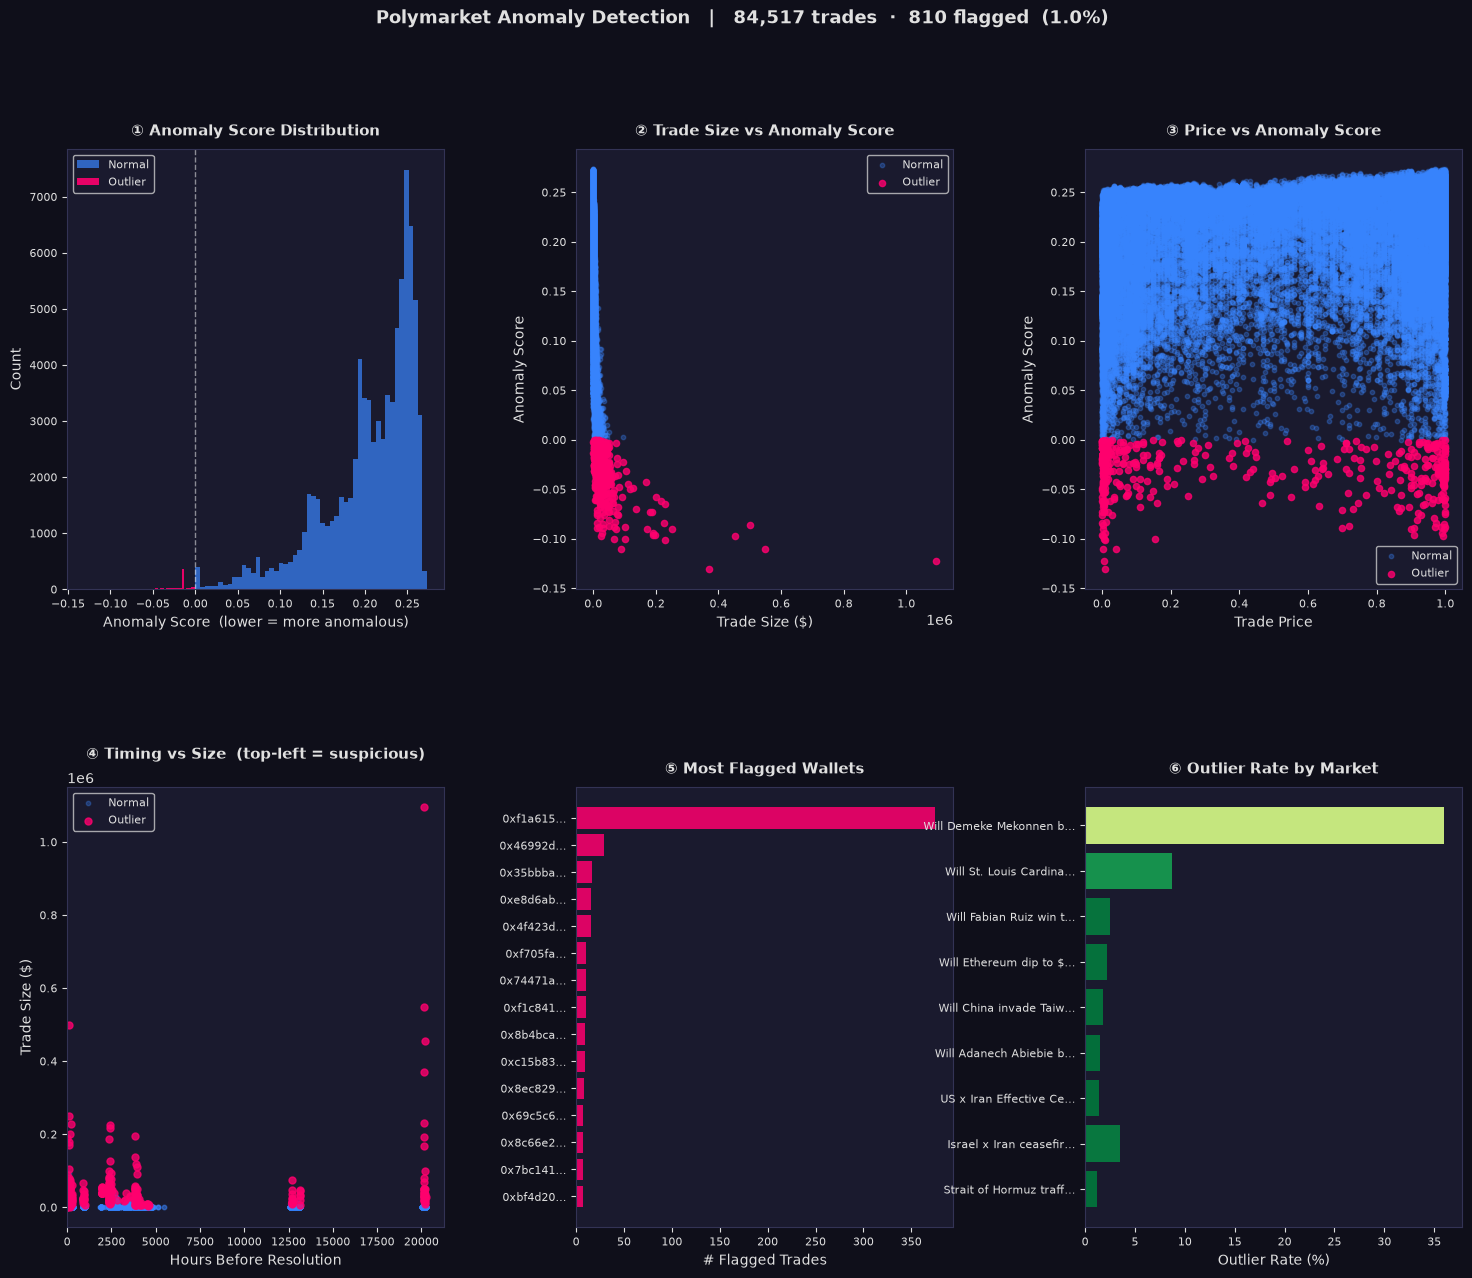

Saved → anomaly_dashboard.png


In [19]:
# CELL 9 — VISUALIZE ANOMALIES
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import numpy as np

fig = plt.figure(figsize=(18, 14))
fig.patch.set_facecolor("#0f0f1a")
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

NORMAL_COL  = "#3a86ff"
OUTLIER_COL = "#ff006e"
TEXT_COL    = "#e0e0e0"

def style_ax(ax, title):
    ax.set_facecolor("#1a1a2e")
    ax.set_title(title, color=TEXT_COL, fontsize=11, fontweight="bold", pad=10)
    ax.tick_params(colors=TEXT_COL, labelsize=8)
    for spine in ax.spines.values():
        spine.set_edgecolor("#333355")
    ax.xaxis.label.set_color(TEXT_COL)
    ax.yaxis.label.set_color(TEXT_COL)

normal  = feature_df[feature_df["anomaly"] ==  1]
outlier = feature_df[feature_df["anomaly"] == -1]

# ── 1. ANOMALY SCORE DISTRIBUTION ──────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(normal["anomaly_score"],  bins=50, color=NORMAL_COL,  alpha=0.7, label="Normal")
ax1.hist(outlier["anomaly_score"], bins=50, color=OUTLIER_COL, alpha=0.9, label="Outlier")
ax1.axvline(x=0, color="white", linestyle="--", linewidth=1, alpha=0.5)
ax1.set_xlabel("Anomaly Score  (lower = more anomalous)")
ax1.set_ylabel("Count")
ax1.legend(facecolor="#1a1a2e", labelcolor=TEXT_COL, fontsize=8)
style_ax(ax1, "① Anomaly Score Distribution")

# ── 2. TRADE SIZE vs ANOMALY SCORE ─────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(normal["size"],  normal["anomaly_score"],
            c=NORMAL_COL,  alpha=0.3, s=10, label="Normal")
ax2.scatter(outlier["size"], outlier["anomaly_score"],
            c=OUTLIER_COL, alpha=0.8, s=20, label="Outlier")
ax2.set_xlabel("Trade Size ($)")
ax2.set_ylabel("Anomaly Score")
ax2.legend(facecolor="#1a1a2e", labelcolor=TEXT_COL, fontsize=8)
style_ax(ax2, "② Trade Size vs Anomaly Score")

# ── 3. PRICE vs ANOMALY SCORE ───────────────────────────────
ax3 = fig.add_subplot(gs[0, 2])
ax3.scatter(normal["price"],  normal["anomaly_score"],
            c=NORMAL_COL,  alpha=0.3, s=10, label="Normal")
ax3.scatter(outlier["price"], outlier["anomaly_score"],
            c=OUTLIER_COL, alpha=0.8, s=20, label="Outlier")
ax3.set_xlabel("Trade Price")
ax3.set_ylabel("Anomaly Score")
ax3.legend(facecolor="#1a1a2e", labelcolor=TEXT_COL, fontsize=8)
style_ax(ax3, "③ Price vs Anomaly Score")

# ── 4. HOURS TO RESOLUTION vs SIZE ─────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
ax4.scatter(normal["hours_to_resolution"],  normal["size"],
            c=NORMAL_COL,  alpha=0.3, s=10, label="Normal")
ax4.scatter(outlier["hours_to_resolution"], outlier["size"],
            c=OUTLIER_COL, alpha=0.8, s=25, label="Outlier")
ax4.set_xlabel("Hours Before Resolution")
ax4.set_ylabel("Trade Size ($)")
ax4.set_xlim(left=0)
ax4.legend(facecolor="#1a1a2e", labelcolor=TEXT_COL, fontsize=8)
style_ax(ax4, "④ Timing vs Size  (top-left = suspicious)")

# ── 5. TOP 15 WALLETS BY OUTLIER COUNT ─────────────────────
ax5 = fig.add_subplot(gs[1, 1])
top_wallets = (
    outlier.groupby("wallet")
    .agg(outlier_trades=("anomaly_score", "count"),
         avg_score=("anomaly_score", "mean"),
         total_size=("size", "sum"))
    .sort_values("outlier_trades", ascending=False)
    .head(15)
)
short_labels = [w[:8] + "…" for w in top_wallets.index]
bars = ax5.barh(short_labels[::-1], top_wallets["outlier_trades"].values[::-1],
                color=OUTLIER_COL, alpha=0.85)
ax5.set_xlabel("# Flagged Trades")
style_ax(ax5, "⑤ Most Flagged Wallets")

# ── 6. OUTLIER RATE PER MARKET ──────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
market_stats = feature_df.groupby("market_title").apply(
    lambda g: pd.Series({
        "total":        len(g),
        "outliers":     (g["anomaly"] == -1).sum(),
        "outlier_rate": (g["anomaly"] == -1).mean() * 100,
    })
).reset_index()
market_stats = market_stats[market_stats["total"] >= 5].sort_values("outlier_rate", ascending=False).head(12)
short_mkt = [t[:22] + "…" if len(t) > 22 else t for t in market_stats["market_title"]]
colors = plt.cm.RdYlGn_r(market_stats["outlier_rate"].values / 100)
ax6.barh(short_mkt[::-1], market_stats["outlier_rate"].values[::-1], color=colors[::-1])
ax6.set_xlabel("Outlier Rate (%)")
style_ax(ax6, "⑥ Outlier Rate by Market")

# ── SUMMARY TITLE ───────────────────────────────────────────
total    = len(feature_df)
n_out    = len(outlier)
flag_pct = n_out / total * 100
fig.suptitle(
    f"Polymarket Anomaly Detection   |   {total:,} trades  ·  {n_out:,} flagged  ({flag_pct:.1f}%)",
    color=TEXT_COL, fontsize=13, fontweight="bold", y=0.98
)

plt.savefig("anomaly_dashboard.png", dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()
print("Saved → anomaly_dashboard.png")

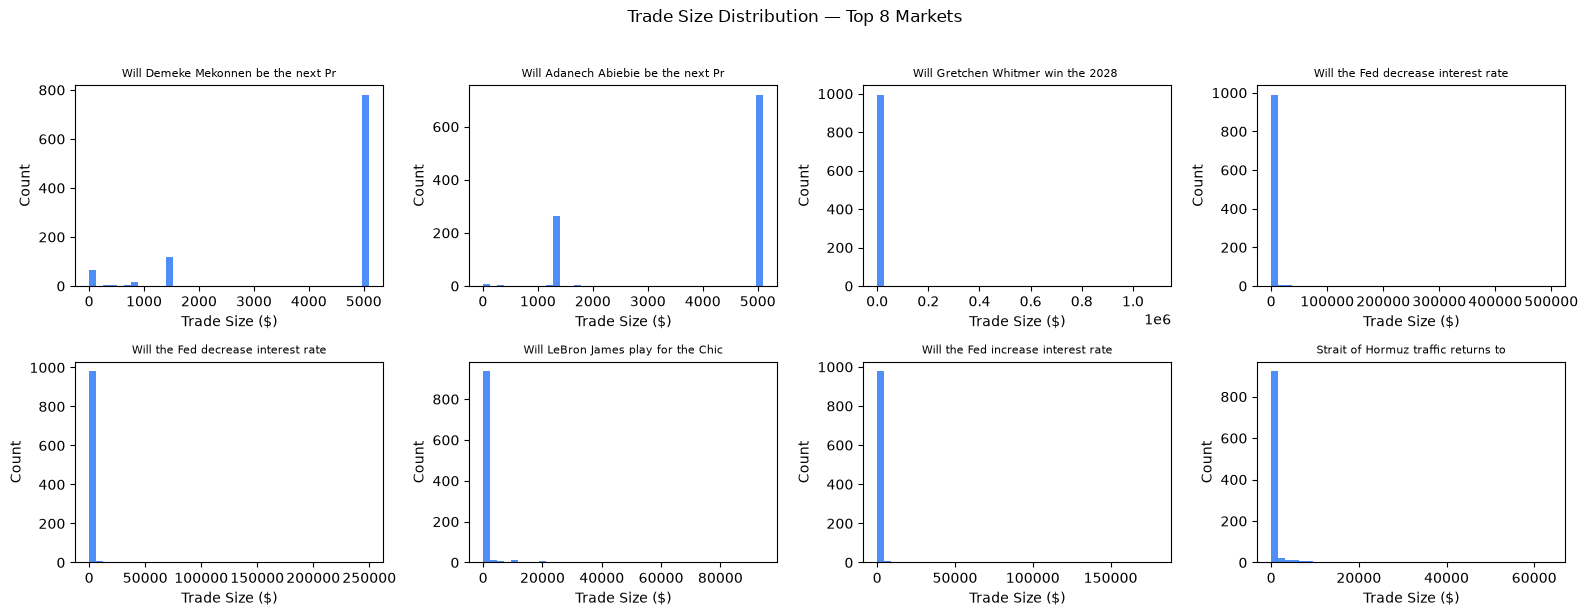

In [20]:
# CELL — PLOT TRADE SIZE DISTRIBUTION FOR TOP MARKETS
import matplotlib.pyplot as plt

top_markets = (
    trades_df.groupby("market_title")["size"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
    .index.tolist()
)

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
axes = axes.flatten()

for i, market in enumerate(top_markets):
    data = trades_df[trades_df["market_title"] == market]["size"]
    axes[i].hist(data, bins=40, color="#4f8ef7", edgecolor="none")
    axes[i].set_title(market[:35], fontsize=8)
    axes[i].set_xlabel("Trade Size ($)")
    axes[i].set_ylabel("Count")

plt.suptitle("Trade Size Distribution — Top 8 Markets", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

In [21]:
# CELL 10e — SAVE FINAL VALIDATION RESULTS
import json

results_summary = {
    "run_date": pd.Timestamp.now().isoformat(),
    "contamination": 0.08,
    "restrict_to_early": True,
    "n_flagged": 7,
    "n_unflagged": 74,
    "flagged_hit_rate": 0.714,
    "unflagged_hit_rate": 0.419,
    "lift_pp": 29.5,
}

with open("backtest_results.json", "w") as f:
    json.dump(results_summary, f, indent=2)

print("Saved backtest_results.json")

Saved backtest_results.json


In [22]:
# CELL 10f — SAVE ANOMALY RESULTS TO DATABASE
closed_feature_df.to_sql("closed_market_backtest", conn, if_exists="replace", index=False)
conn.commit()
print(f"Saved {len(closed_feature_df)} rows to closed_market_backtest table")

Saved 6930 rows to closed_market_backtest table


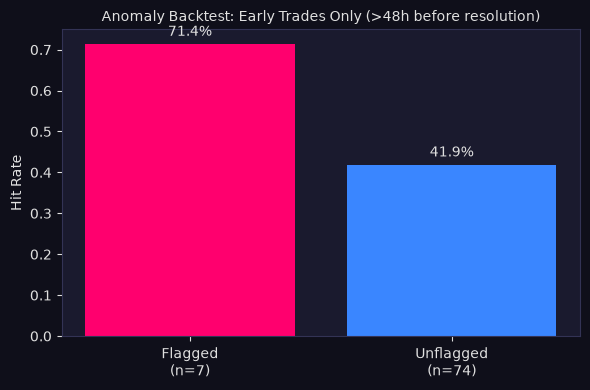

Saved backtest_summary.png


In [23]:
# CELL 10g — BACKTEST SUMMARY CHART
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
fig.patch.set_facecolor("#0f0f1a")
ax.set_facecolor("#1a1a2e")

bars = ax.bar(["Flagged\n(n=7)", "Unflagged\n(n=74)"],
               [0.714, 0.419],
               color=["#ff006e", "#3a86ff"])
ax.set_ylabel("Hit Rate", color="#e0e0e0")
ax.set_title("Anomaly Backtest: Early Trades Only (>48h before resolution)",
             color="#e0e0e0", fontsize=10)
ax.tick_params(colors="#e0e0e0")
for spine in ax.spines.values():
    spine.set_edgecolor("#333355")

for bar, val in zip(bars, [0.714, 0.419]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.1%}",
            ha="center", color="#e0e0e0", fontsize=10)

plt.tight_layout()
plt.savefig("backtest_summary.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()
print("Saved backtest_summary.png")